In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
data = {
    "x": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "y": [1.2, 3.8, 8.5, 15.3, 23.5, 36.5, 48.0, 64.5, 80.0, 101.0, 120.0, 145.0]
}

df = pd.DataFrame(data)

x = df[["x"]]
y = df[["y"]]

print(df)

     x      y
0    1    1.2
1    2    3.8
2    3    8.5
3    4   15.3
4    5   23.5
5    6   36.5
6    7   48.0
7    8   64.5
8    9   80.0
9   10  101.0
10  11  120.0
11  12  145.0


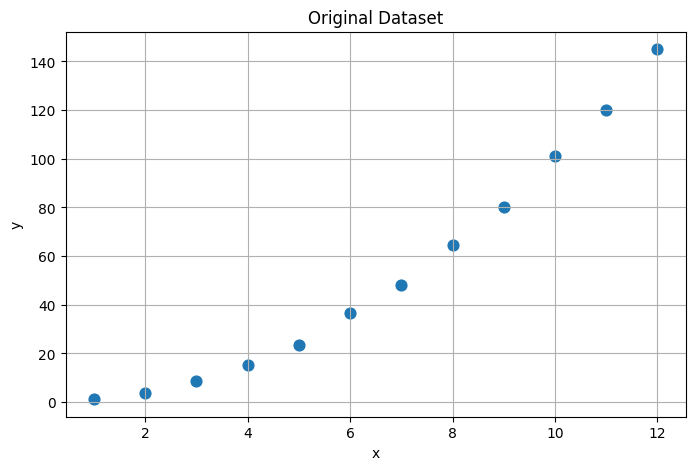

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, s = 60)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original Dataset")

plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


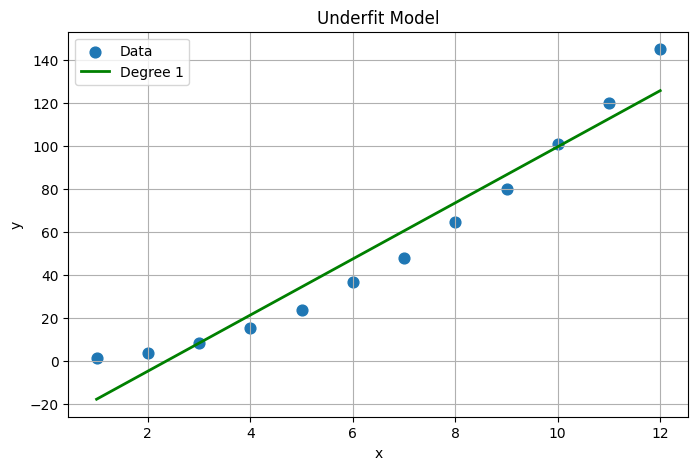

In [ ]:
model_underfit = Pipeline([
    ("poly", PolynomialFeatures(degree = 1)),
    ("lin_reg", LinearRegression())
])
model_underfit.fit(x, y)
x_plot = np.linspace(1, 12, 300).reshape(-1, 1)
y_pred_underfit = model_underfit.predict(x_plot)
plt.figure(figsize = (8, 5))
plt.scatter(x, y, s = 60, label = "Data")
plt.plot(x_plot, y_pred_underfit, linewidth = 2,label = "Degree 1", color = "green")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Underfit Model")
plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


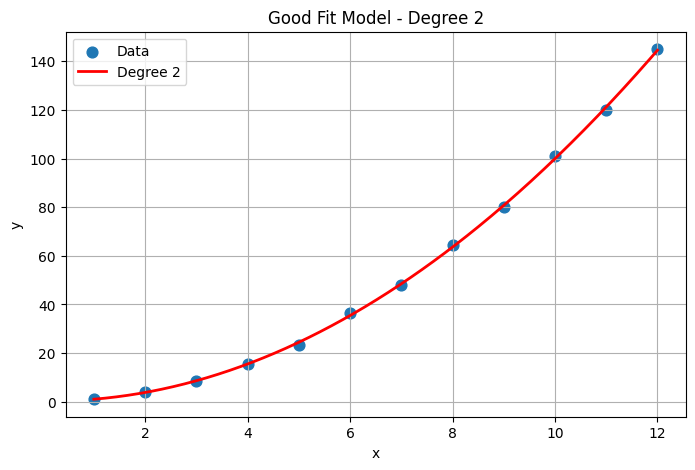

In [ ]:
model_good = Pipeline([
    ("poly", PolynomialFeatures(degree = 2)),
    ("lin_reg", LinearRegression())
])
model_good.fit(x, y)
y_pred_good = model_good.predict(x_plot)
plt.figure(figsize = (8, 5))
plt.scatter(x, y, s = 60, label = "Data")
plt.plot(x_plot, y_pred_good, linewidth = 2, label = "Degree 2", color = "red")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Good Fit Model - Degree 2")
plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


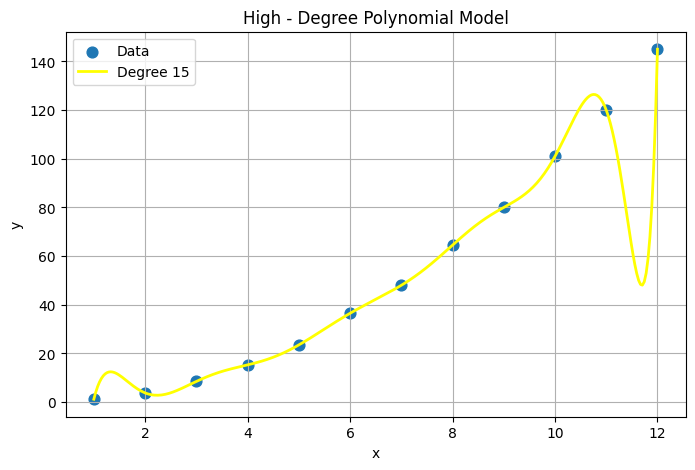

In [ ]:
model_overfit = Pipeline([
    ("poly", PolynomialFeatures(degree = 15)),
    ("scale", StandardScaler()),
    ("lin_reg", LinearRegression())
])
model_overfit.fit(x, y)
y_pred_overfit = model_overfit.predict(x_plot)
plt.figure(figsize = (8, 5))
plt.scatter(x, y, s = 60, label = "Data", )
plt.plot(x_plot, y_pred_overfit, linewidth = 2, label = "Degree 15", color = "yellow")
plt.xlabel("x")
plt.ylabel("y")
plt.title("High - Degree Polynomial Model")
plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


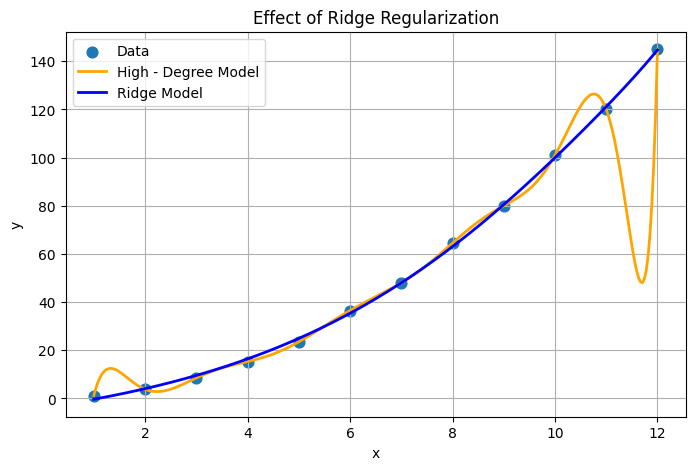

In [ ]:
ridge_model = Pipeline ([
    ("poly", PolynomialFeatures(degree = 15)),
    ("scale", StandardScaler()),
    ("ridge", Ridge(alpha = 0.05))
])
ridge_model.fit(x, y)
y_pred_ridge = ridge_model.predict(x_plot)
plt.figure(figsize = (8, 5))
plt.scatter(x, y, s = 60, label = "Data")
plt.plot(x_plot, y_pred_overfit, linewidth = 2, label = "High - Degree Model", color = "orange")
plt.plot(x_plot, y_pred_ridge, linewidth = 2, label = "Ridge Model", color = "blue")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Effect of Ridge Regularization")
plt.legend()
plt.grid(True)
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


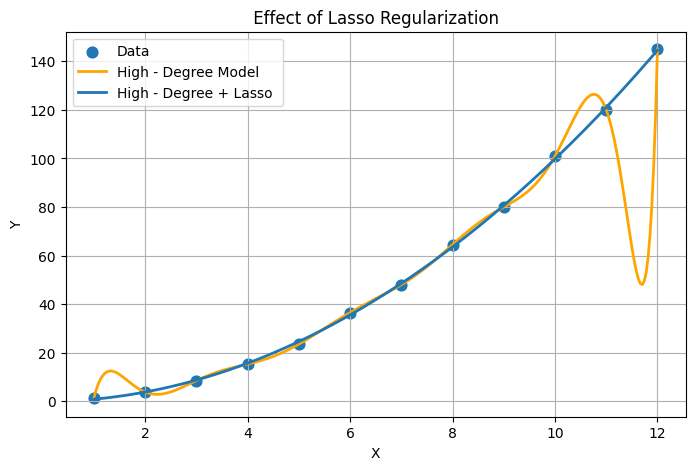

In [ ]:
lasso_model = Pipeline ([
    ("poly", PolynomialFeatures(degree = 15)),
    ("scale", StandardScaler()),
    ("lasso", Lasso(alpha = 0.05, max_iter = 100000))
])
lasso_model.fit(x, y)
y_pred_lasso = lasso_model.predict(x_plot)
plt.figure(figsize = (8, 5))
plt.scatter(x, y, s = 60, label = "Data")
plt.plot(x_plot, y_pred_overfit, linewidth = 2, label = "High - Degree Model", color = "orange")
plt . plot (x_plot , y_pred_lasso ,linewidth =2 , label ="High - Degree + Lasso " )
plt.xlabel ("X")
plt.ylabel ("Y")
plt.title (" Effect of Lasso Regularization ")
plt.legend()
plt.grid(True)
plt.show()

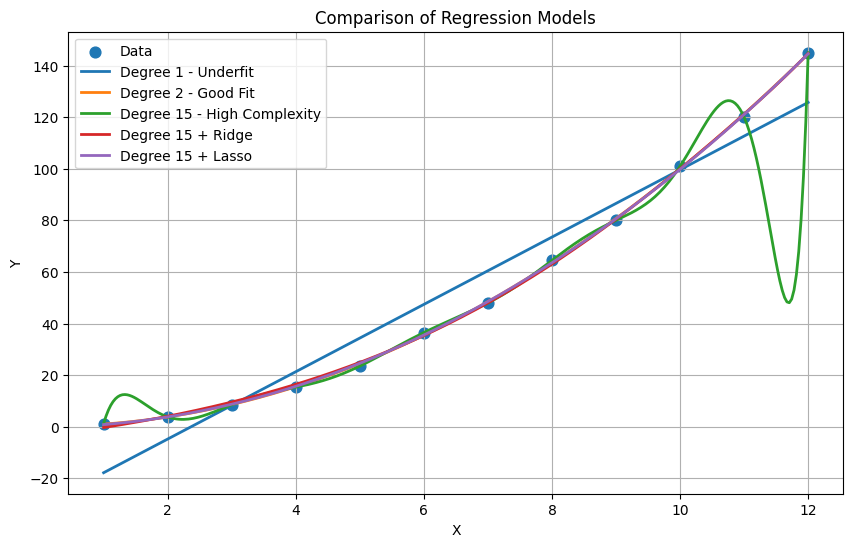

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(x, y, s=60, label="Data")
plt.plot(x_plot, y_pred_underfit, linewidth=2, label="Degree 1 - Underfit")
plt.plot(x_plot,y_pred_good, linewidth=2,  lambdaabel="Degree 2 - Good Fit")
plt.plot(x_plot, y_pred_overfit, linewidth=2, label="Degree 15 - High Complexity")
plt.plot(x_plot, y_pred_ridge, linewidth=2, label="Degree 15 + Ridge")
plt.plot(x_plot, y_pred_lasso, linewidth=2, label="Degree 15 + Lasso")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Comparison of Regression Models")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
models = {
    "Degree 1": model_underfit,
    "Degree 2": model_good,
    "Degree 15": model_overfit,
    "Degree 15 + Ridge": ridge_model,
    "Degree 15 + Lasso": lasso_model
}

results = []

for name, model in models.items():
    prediction = model.predict(x)

    mse = mean_squared_error(y, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, prediction)

    results.append([name, mse, rmse, r2])

results_df = pd.DataFrame(results,columns=["Model", "MSE", "RMSE", "R2"])



In [ ]:
alphas = [0.01, 0.1, 1, 10, 100]

for alpha in alphas:

    ridge = Pipeline([
        ("poly", PolynomialFeatures(degree=15)),
        ("scale", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])

    ridge.fit(x, y)

    prediction = ridge.predict(x)

    mse = mean_squared_error(y, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, prediction)

    print(
        "Alpha:", alpha,
        "MSE:", round(mse, 4),
        "RMSE:", round(rmse, 4),
        "R2:", round(r2, 4)
    )

Alpha: 0.01 MSE: 0.5773 RMSE: 0.7598 R2: 0.9997
Alpha: 0.1 MSE: 1.585 RMSE: 1.259 R2: 0.9993
Alpha: 1 MSE: 5.7201 RMSE: 2.3917 R2: 0.9973
Alpha: 10 MSE: 94.826 RMSE: 9.7379 R2: 0.9559
Alpha: 100 MSE: 589.5144 RMSE: 24.2799 R2: 0.7256
